# Two-spiral classification with an MLP

A 2 → 5×5 hidden → 1 network with sigmoid activations, trained on the cross-entropy cost with Adam.

In [ ]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
np.random.seed(0); torch.manual_seed(0)

## Data: two interleaved spirals

In [ ]:
#@title Create a dataset of $(x,y)$ pairs together with a label of each pair being in class 0 or class 1.

n = 200
t = np.sqrt(np.random.rand(n)) * 3 * np.pi
arm = np.c_[t * np.cos(t), t * np.sin(t)] / (3 * np.pi) + 0.03 * np.random.randn(n, 2)
X = torch.tensor(np.r_[arm, -arm], dtype=torch.float32)
y = torch.cat([torch.zeros(n), torch.ones(n)]).unsqueeze(1)

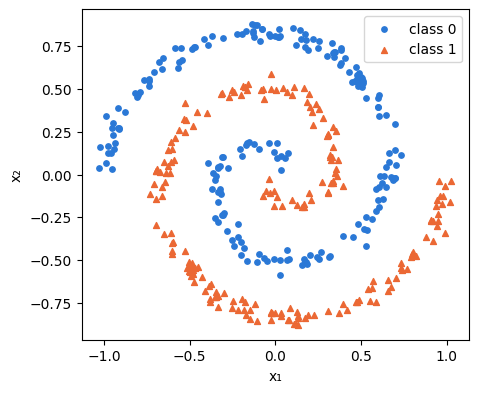

In [ ]:
#@title Plot the data

Xn, yv = X.numpy(), y.ravel().numpy()
plt.figure(figsize=(5, 5))
plt.scatter(*Xn[yv == 0].T, s=15, c="#2a78d6", label="class 0")
plt.scatter(*Xn[yv == 1].T, s=18, c="#eb6834", marker="^", label="class 1")
plt.gca().set_aspect("equal"); plt.xlabel("x₁"); plt.ylabel("x₂"); plt.legend(); plt.show()

## Model: 2 inputs → 5 hidden layers of 5 sigmoid neurons → 1 output

In [ ]:
#@title Initialise the neural network architecture according to seating plan in classroom: layer structure, and sigmoid functions acting on linear functions

sizes = [2, 6, 5, 3, 4, 5, 1]
layers = [nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:])]
model = nn.Sequential(*[m for l in layers[:-1] for m in (l, nn.Sigmoid())], layers[-1])

## Initial weights and biases

One `(W, b)` pair per layer. Each row of W is one neuron, with one weight per input to that layer. Set `manual = None` to use PyTorch's random initialisation instead. The initialisation below was decided by the students in the tutorial!

In [ ]:
#@title Plugging in weights and biases that students gave us

manual = [  # one (W, b) per layer; each row of W is one neuron, set manual = None for random init
    # hidden layer 1 (W: 6x2, b: 6)
    ([[ 0.6,  0.33],
      [1, -1],
      [0.67, 0.69],
      [ 100, 100],
      [ 1, 1],
      [ -0.63, -0.78]],
     [ 0.55,  4, 0.10,  4, 1, -0.69]),
    # hidden layer 2 (W: 5x6, b: 5)
    ([[0.1, 0.3, 0.4, 0.5, 0.7,-0.3],
      [ 0.2, 0.8, -0.3,  -0.5,  -1,1],
      [ 0.2,  0.5, -0.6, -0.3,  -1,0.8],
      [ -1, -1,  -1,  -1,  -1,-1],
      [ 0.7, -0.4,  0.3, 0.67, 0.7,-0.14]],
     [ 0.5,  np.pi/4,  np.exp(3), 0,  -0.5]),
    # hidden layer 3 (W: 3x5, b: 3)
    ([[ 0.8,  0.7,  -1, 0.5,  0.2],
      [ 0.4,  1.9, -2.8,  0.35, 1.25],
      [3,  9,  29,  562, 20]],
     [-1, 12,  60]),
    # hidden layer 4 (W: 4x3, b: 4)
    ([[1,  2,  3],
      [ 27, 9,  3],
      [0.1,  0.2, 0.3],
      [-0.94,    0.53,  4]],
     [ 5, 67,  0.25,-1]),
    # hidden layer 5 (W: 5x4, b: 5)
    ([[6,  -8, 2,10],
      [0.2, -0.5, 0.8,-0.1],
      [-0.052, 0.114, 0.089,-0.01],
      [ 0.294,  0.743,  0.984,0.562],
      [0.69,0.79,0.89,0.99]],
     [5,  0,  0,  0,6.7]),
    # output layer (W: 1x5, b: 1)
    ([[ 35,  5,  12,  24,102]],
     [7]),
]

if manual:
    with torch.no_grad():
        for l, (W, b) in zip(layers, manual):
            l.weight.copy_(torch.tensor(W)); l.bias.copy_(torch.tensor(b))

## Forward pass before training

Pick any input point and see what the untrained network (with the manual weights) does with it, layer by layer.

In [ ]:
#@title Evaluate model on $(0,0.8)$ which should be class 0

x_new = torch.tensor([[0.0, 0.8]])   # the input (x1, x2): on the class 0 (blue) arm - change to any point

def forward_pass(x):
    a = x
    with torch.no_grad():
        for i, l in enumerate(layers, 1):
            z = l(a)                                     # z = W a + b
            a = torch.sigmoid(z) if i < len(layers) else z
            name = f"hidden layer {i} a" if i < len(layers) else "output z"
            print(f"{name:18s} = {a.numpy().round(3).ravel()}")
        p = torch.sigmoid(a).item()
    print(f"\nf(x) = P(class 1) = {p:.3f}  ->  prediction = class {int(p >= 0.5)}")

forward_pass(x_new)

hidden layer 1 a   = [0.693 0.961 0.657 1.    0.858 0.212]
hidden layer 2 a   = [0.896 0.586 1.    0.012 0.739]
hidden layer 3 a   = [0.328 1.    1.   ]
hidden layer 4 a   = [1.    1.    0.686 0.962]
hidden layer 5 a   = [1.    0.538 0.528 0.905 1.   ]
output z           = [174.742]

f(x) = P(class 1) = 1.000  ->  prediction = class 1


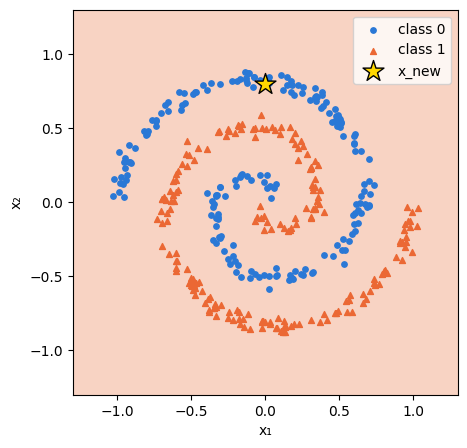

In [ ]:
#@title Plot untrained network output

g = torch.linspace(-1.3, 1.3, 300)
G1, G2 = torch.meshgrid(g, g, indexing="xy")
with torch.no_grad():
    P = torch.sigmoid(model(torch.stack([G1.ravel(), G2.ravel()], 1))).reshape(G1.shape)
plt.figure(figsize=(5, 5))
plt.contourf(G1.numpy(), G2.numpy(), P.numpy(), levels=[0, 0.5, 1], colors=["#cfe1f6", "#f8d3c3"])
plt.contour(G1.numpy(), G2.numpy(), P.numpy(), levels=[0.5], colors="k", linewidths=1.5)
plt.scatter(*Xn[yv == 0].T, s=15, c="#2a78d6", label="class 0")
plt.scatter(*Xn[yv == 1].T, s=18, c="#eb6834", marker="^", label="class 1")
plt.scatter(*x_new[0], s=250, c="gold", marker="*", edgecolor="k", label="x_new", zorder=5)
plt.gca().set_aspect("equal"); plt.xlabel("x₁"); plt.ylabel("x₂"); plt.legend(); plt.show()

Clearly a terrible starting point; this model thinks that every pair $(x_1,x_2)$ is class 1. This was because the students/neurons are not good random number generators; we predominantly choose positive weights and biases...

## Train with Adam (gradient descent with adaptive step sizes)

In [ ]:
#@title Training

loss_fn = nn.BCEWithLogitsLoss()                      # sigmoid output + cross-entropy cost J
opt = torch.optim.Adam(model.parameters(), lr=0.01)  # plain GD (torch.optim.SGD) stalls at chance on this deep sigmoid net
for epoch in range(50001):
    opt.zero_grad()
    loss = loss_fn(model(X), y)
    loss.backward()                                   # backprop: dJ/dw, dJ/db
    opt.step()                                        # w <- w - lr * dJ/dw
    if epoch % 500 == 0:
        acc = ((model(X) > 0).float() == y).float().mean()
        print(f"epoch {epoch:5d}  J = {loss.item():.4f}  accuracy = {acc:.1%}")

epoch     0  J = 87.3710  accuracy = 50.0%
epoch   500  J = 1.3769  accuracy = 50.0%
epoch  1000  J = 0.6946  accuracy = 50.0%
epoch  1500  J = 0.6931  accuracy = 50.0%
epoch  2000  J = 0.6931  accuracy = 42.0%
epoch  2500  J = 0.6931  accuracy = 42.3%
epoch  3000  J = 0.6931  accuracy = 43.8%
epoch  3500  J = 0.6931  accuracy = 45.2%
epoch  4000  J = 0.6931  accuracy = 48.2%
epoch  4500  J = 0.6931  accuracy = 54.0%
epoch  5000  J = 0.6931  accuracy = 65.8%
epoch  5500  J = 0.6931  accuracy = 66.0%
epoch  6000  J = 0.6931  accuracy = 65.0%
epoch  6500  J = 0.6931  accuracy = 65.8%
epoch  7000  J = 0.6927  accuracy = 66.0%
epoch  7500  J = 0.6046  accuracy = 70.0%
epoch  8000  J = 0.6022  accuracy = 70.0%
epoch  8500  J = 0.6014  accuracy = 70.0%
epoch  9000  J = 0.6009  accuracy = 70.0%
epoch  9500  J = 0.5998  accuracy = 70.0%
epoch 10000  J = 0.5974  accuracy = 70.0%
epoch 10500  J = 0.5945  accuracy = 70.0%
epoch 11000  J = 0.5881  accuracy = 70.5%
epoch 11500  J = 0.5851  accuracy

## Forward pass after training

The same input through the trained network.

In [ ]:
forward_pass(x_new)

hidden layer 1 a   = [0.764 0.045 0.    1.    0.227 0.   ]
hidden layer 2 a   = [1. 0. 1. 1. 1.]
hidden layer 3 a   = [0.    0.386 1.   ]
hidden layer 4 a   = [1.    1.    0.    0.142]
hidden layer 5 a   = [0.007 0.    0.    0.    0.023]
output z           = [-12.134]

f(x) = P(class 1) = 0.000  ->  prediction = class 0


## Trained weights and biases

In [ ]:
#@title output trained weight and bias values

for i, l in enumerate(layers, 1):
    print(f"\nlayer {i}\nW =\n{l.weight.data}\nb = {l.bias.data}")


layer 1
W =
tensor([[  3.8962,  -2.5008],
        [ -6.3072, -22.3715],
        [ -0.7546, -37.8557],
        [ 86.9057, 108.0835],
        [  2.5938,   2.4666],
        [ -0.3245, -32.6731]])
b = tensor([ 3.1760, 14.8382, -1.2005,  6.6312, -3.1992, -0.7872])

layer 2
W =
tensor([[  0.0762,   2.7816, -15.4089,   6.5754,   4.2166, -14.0796],
        [ -2.3168,  -3.6563,  10.9889,  -1.3961,  -8.6094,  11.1368],
        [  0.2000,   0.5000,  -0.6000,  -0.3000,  -1.0000,   0.8000],
        [ -5.6715,   7.2776, -13.9350,   7.5404,  -8.4301,  -8.3276],
        [ 13.9031,  -8.3962,  -0.0608,  -7.8231,  23.6357,   2.6587]])
b = tensor([ 2.8064, -2.9809, 20.0855,  7.9349,  0.6365])

layer 3
W =
tensor([[ -9.2575,  11.1931,  -7.4986,  35.6385, -20.1982],
        [ 15.6415,  -8.1882,  -9.3378,  13.8964, -26.1301],
        [  3.0000,   9.0000,  29.0000, 562.0000,  20.0000]])
b = tensor([-7.4986,  5.4620, 60.0000])

layer 4
W =
tensor([[-17.3069,  41.7045,   2.4714],
        [ 27.0000,   9.0000,  

## Decision boundary

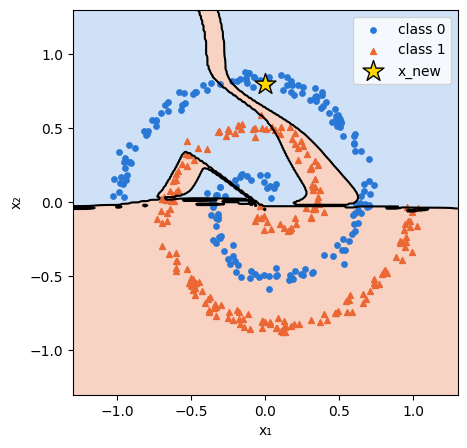

In [ ]:
#@title Plot trained network outputs

g = torch.linspace(-1.3, 1.3, 300)
G1, G2 = torch.meshgrid(g, g, indexing="xy")
with torch.no_grad():
    P = torch.sigmoid(model(torch.stack([G1.ravel(), G2.ravel()], 1))).reshape(G1.shape)
plt.figure(figsize=(5, 5))
plt.contourf(G1.numpy(), G2.numpy(), P.numpy(), levels=[0, 0.5, 1], colors=["#cfe1f6", "#f8d3c3"])
plt.contour(G1.numpy(), G2.numpy(), P.numpy(), levels=[0.5], colors="k", linewidths=1.5)
plt.scatter(*Xn[yv == 0].T, s=15, c="#2a78d6", label="class 0")
plt.scatter(*Xn[yv == 1].T, s=18, c="#eb6834", marker="^", label="class 1")
plt.scatter(*x_new[0], s=250, c="gold", marker="*", edgecolor="k", label="x_new", zorder=5)
plt.gca().set_aspect("equal"); plt.xlabel("x₁"); plt.ylabel("x₂"); plt.legend(); plt.show()

Looks pretty bad. This model is failing to understand what makes a data point class 0 or class 1, and you can see roughly how it is trying to extrapolate what it knows to no avail.

## Repeating with a good initialisation

In [ ]:
sizes = [2, 5, 5, 5, 5, 5, 1]
layers = [nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:])]
model = nn.Sequential(*[m for l in layers[:-1] for m in (l, nn.Sigmoid())], layers[-1])

In [ ]:
# @title Picking starting weights and biases with a better spread of positive and negative values

manual = [  # one (W, b) per layer; each row of W is one neuron, set manual = None for random init
    # hidden layer 1 (W: 5x2, b: 5)
    ([[ 0.02,  0.90],
      [-0.71,  0.90],
      [-0.38, -0.15],
      [ 0.66, -0.18],
      [ 0.10, -0.94]],
     [ 0.15,  0.02, -0.10,  0.17, -0.12]),
    # hidden layer 2 (W: 5x5, b: 5)
    ([[-0.09, -0.73, -0.19, -0.59, -0.48],
      [ 0.50, -0.44, -0.03,  0.96,  0.92],
      [ 0.45,  0.08, -0.45, -0.68,  0.94],
      [ 0.03, -0.77,  0.25,  0.55,  0.23],
      [ 0.83, -0.92,  0.06, -0.08, -0.88]],
     [ 0.08,  0.21,  0.06, -0.14,  0.20]),
    # hidden layer 3 (W: 5x5, b: 5)
    ([[ 0.02,  0.02,  0.51, -0.70,  0.64],
      [ 0.37,  0.57, -0.62,  0.60, -0.62],
      [-0.84,  0.71,  0.72,  0.75, -0.06],
      [-0.45, -0.99,  0.29,  0.44,  0.67],
      [-0.44, -0.57,  0.28,  0.61,  0.93]],
     [-0.21, -0.01,  0.24, -0.05,  0.05]),
    # hidden layer 4 (W: 5x5, b: 5)
    ([[-0.95,  0.35,  0.84,  0.65,  0.77],
      [ 0.32, -0.51,  0.54, -0.58,  0.66],
      [-0.87,  0.65, -0.67, -0.25, -0.37],
      [ 0.38, -0.64, -0.21, -0.99, -0.48],
      [-0.16, -0.79,  0.27, -0.24,  0.45]],
     [ 0.09, -0.04,  0.22,  0.08,  0.19]),
    # hidden layer 5 (W: 5x5, b: 5)
    ([[-0.32,  0.09, -0.61,  0.99, -0.51],
      [-0.49, -0.85, -0.48,  0.53,  0.40],
      [-0.74, -0.25, -0.16,  0.33, -0.09],
      [ 0.17,  0.68,  0.45, -0.27, -0.10],
      [-0.26, -0.78, -0.59, -0.43, -0.37]],
     [-0.11,  0.05,  0.28,  0.16,  0.17]),
    # output layer (W: 1x5, b: 1)
    ([[ 0.52,  0.19,  0.84,  0.38,  0.00]],
     [-0.25]),
]

if manual:
    with torch.no_grad():
        for l, (W, b) in zip(layers, manual):
            l.weight.copy_(torch.tensor(W)); l.bias.copy_(torch.tensor(b))

In [ ]:
#@title Training the network

loss_fn = nn.BCEWithLogitsLoss()                      # sigmoid output + cross-entropy cost J
opt = torch.optim.Adam(model.parameters(), lr=0.01)  # plain GD (torch.optim.SGD) stalls at chance on this deep sigmoid net
for epoch in range(5001):
    opt.zero_grad()
    loss = loss_fn(model(X), y)
    loss.backward()                                   # backprop: dJ/dw, dJ/db
    opt.step()                                        # w <- w - lr * dJ/dw
    if epoch % 500 == 0:
        acc = ((model(X) > 0).float() == y).float().mean()
        print(f"epoch {epoch:5d}  J = {loss.item():.4f}  accuracy = {acc:.1%}")

epoch     0  J = 0.7371  accuracy = 50.0%
epoch   500  J = 0.0971  accuracy = 96.0%
epoch  1000  J = 0.0117  accuracy = 99.5%
epoch  1500  J = 0.0046  accuracy = 99.8%
epoch  2000  J = 0.0010  accuracy = 100.0%
epoch  2500  J = 0.0003  accuracy = 100.0%
epoch  3000  J = 0.0002  accuracy = 100.0%
epoch  3500  J = 0.0001  accuracy = 100.0%
epoch  4000  J = 0.0001  accuracy = 100.0%
epoch  4500  J = 0.0000  accuracy = 100.0%
epoch  5000  J = 0.0000  accuracy = 100.0%


Only 5000 epochs are needed compared to the 50k before, and we are already at 100% accuracy.

In [ ]:
#@title Show the trained weights and biases

for i, l in enumerate(layers, 1):
    print(f"\nlayer {i}\nW =\n{l.weight.data}\nb = {l.bias.data}")


layer 1
W =
tensor([[  4.3594,   5.9869],
        [  7.5456,   0.9244],
        [ -2.4960,  10.3125],
        [  5.6092,  -3.5405],
        [ -1.2784, -11.4938]])
b = tensor([-0.7184,  3.7599,  3.5769, -0.4116,  3.2601])

layer 2
W =
tensor([[ -0.1772,  -4.1236,  -5.3581,  -5.8711,   2.4705],
        [  7.9629,  -3.7762,  -7.4590,  -2.4125,   2.4569],
        [  3.0208,   1.8755,   8.5278,  -1.3891,  -0.4490],
        [ -2.3886,   0.0864,   2.8478,   2.4845,  -2.9374],
        [  7.2583, -10.7551,   2.0358,   2.6860,  -2.7930]])
b = tensor([ 2.6509,  0.6761,  0.1901, -0.3592, -0.2819])

layer 3
W =
tensor([[ 2.5535,  2.5974, -0.9662,  3.1745, -3.5614],
        [ 3.4173,  4.4557, -1.9514,  4.9504, -4.9150],
        [-4.1557, -2.9590,  2.1217, -4.0733,  4.1405],
        [-3.0468, -3.9324,  1.5083, -4.0224,  5.3150],
        [-2.3756, -3.3789,  1.3636, -3.8960,  5.9601]])
b = tensor([-0.0990, -0.1061, -0.5247,  0.0430,  0.0741])

layer 4
W =
tensor([[-3.5220, -3.6568,  3.1988,  4.0955,  

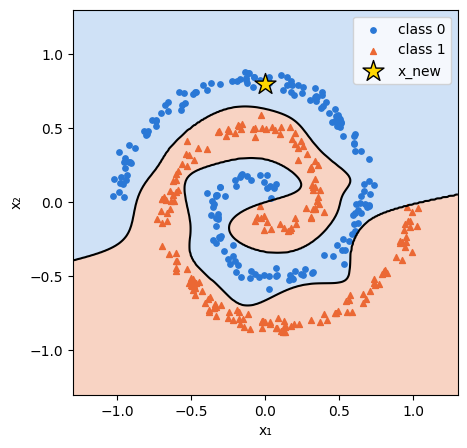

In [ ]:
#@title Plot the decision boundary

g = torch.linspace(-1.3, 1.3, 300)
G1, G2 = torch.meshgrid(g, g, indexing="xy")
with torch.no_grad():
    P = torch.sigmoid(model(torch.stack([G1.ravel(), G2.ravel()], 1))).reshape(G1.shape)
plt.figure(figsize=(5, 5))
plt.contourf(G1.numpy(), G2.numpy(), P.numpy(), levels=[0, 0.5, 1], colors=["#cfe1f6", "#f8d3c3"])
plt.contour(G1.numpy(), G2.numpy(), P.numpy(), levels=[0.5], colors="k", linewidths=1.5)
plt.scatter(*Xn[yv == 0].T, s=15, c="#2a78d6", label="class 0")
plt.scatter(*Xn[yv == 1].T, s=18, c="#eb6834", marker="^", label="class 1")
plt.scatter(*x_new[0], s=250, c="gold", marker="*", edgecolor="k", label="x_new", zorder=5)
plt.gca().set_aspect("equal"); plt.xlabel("x₁"); plt.ylabel("x₂"); plt.legend(); plt.show()

Much better!